# Task 1 · Part 1 — From headlines to a dataset

**Guiding question:** Can Peruvian news headlines be transformed into a reliable news classifier?

The performance of any supervised classifier is ultimately bounded by the quality of the data on which it is trained. Accordingly, this first notebook addresses the data-generation stage of the project: it collects real headlines from a Peruvian newspaper, cleans and normalizes them, and assigns each item to one of four predefined thematic categories. In doing so, it establishes the empirical foundation upon which the subsequent modelling stage rests.

| Parameter | Value |
|---|---|
| **Download date** | 2026-10-18 |
| **Outlet** | Option B — El Comercio (`elcomercio.pe`) |
| **Source of article URLs** | Official section sitemaps: `https://elcomercio.pe/sitemap/web/{section}/?outputType=xml` |
| **Source of article fields** | Metadata of each article page (`og:title`, `og:description`, `article:published_time`) |
| **Sections retrieved** | `politica`, `economia`, `deporte-total`, `tecnologia` |

**Methodological note on the choice of outlet.** La República (Option A) was initially considered. However, a preliminary assessment (Section 1) revealed that each of its RSS feeds exposes only around 21 items, a volume insufficient to reach the required 90–100 news items per category. Consequently, El Comercio was selected, given that its section sitemaps list approximately 100 articles each.

**Ethical considerations.** El Comercio's `robots.txt` explicitly lists these sitemaps for automated access and does not restrict article pages. Furthermore, a pause is introduced between consecutive requests in order to minimize the load imposed on the outlet's servers, in line with responsible web-scraping practices.

In [20]:
import os
import time
from datetime import date

import pandas as pd
import requests
from bs4 import BeautifulSoup
import plotly.express as px

This cell loads the libraries required throughout the notebook. Specifically, `requests` retrieves the documents from the outlet's servers, whereas `BeautifulSoup` parses their XML and HTML structure so that individual fields can be extracted. Subsequently, `pandas` organizes the extracted news into a tabular structure suitable for cleaning and analysis, while `plotly.express` supports the interactive exploratory charts. In addition, `os` creates the required folders, `time` enables the pauses between requests, and `date` records the download date, thereby ensuring the traceability of the dataset.

In [51]:
# =============================================
#  CONFIGURATION
# =============================================

fecha_descarga = date.today().isoformat()

# A descriptive User-Agent tells the outlet who is making the requests and why.
headers = {"User-Agent": "Mozilla/5.0 (Diplomado PUCP - Python Task 1, academic use)"}

# The assignment requires pauses of 1 to 2 seconds between requests.
pausa_segundos = 1.5

# Final source: El Comercio section sitemaps.
secciones = ["politica", "economia", "deporte-total", "tecnologia"]
url_sitemap = "https://elcomercio.pe/sitemap/web/{seccion}/?outputType=xml"

# Kept only for the preliminary assessment of La República (Option A).
url_rss = "https://larepublica.pe/rss/{seccion}.xml"

fecha_descarga

'2026-10-18'

All parameters are centralized in a single configuration cell, which enhances the reproducibility of the notebook: should the collection need to be repeated, only this cell must be modified. In this regard, the descriptive `User-Agent` transparently discloses the academic purpose of the requests, and the 1.5-second pause complies with the assignment's guideline of waiting between one and two seconds per request. Moreover, the `{seccion}` placeholder allows the same URL template to be reused for each of the four sections. Finally, the La República RSS template is retained solely to document the preliminary assessment that motivated the change of outlet.

## 1. Preliminary assessment: La República (Option A)

Before committing to a data source, its capacity to supply the required volume of news was assessed empirically.

In [52]:
# Test La República's politics feed as a sample of its RSS capacity.
respuesta = requests.get(url_rss.format(seccion="politica"), headers=headers, timeout=30)
respuesta.status_code

200

A single test request is sent to La República's politics RSS feed. The resulting status code indicates whether access was granted: `200` confirms a successful request, whereas `403` would signal that the outlet blocked it and `429` that requests were being sent too frequently.

In [23]:
# RSS is XML: each news article lives inside an <item> tag.
sopa = BeautifulSoup(respuesta.content, "xml")
items = sopa.find_all("item")
len(items)

21

Since RSS feeds are structured as XML documents, each news article is enclosed in an `<item>` tag, and `find_all("item")` therefore returns every article available in the feed. Although access was granted (status `200`), the feed exposes only around 21 items. Extrapolating to the four sections, the RSS channel would yield roughly 84 news items, well below the required 350. The outlet's sitemaps and section pages were also inspected manually; nevertheless, none of them exposed more than about 16 items per section. **Accordingly, El Comercio (Option B) was adopted as the data source**, as its section sitemaps list approximately 100 articles each.

## 2. Extraction: collecting article URLs from El Comercio

The extraction proceeds in two stages. First, the section sitemaps are retrieved in order to obtain the list of article URLs; subsequently, each article page is visited to extract its fields. This section addresses the first stage.

In [24]:
# Create the folder for raw backups required by the assignment.
os.makedirs("datos/raw", exist_ok=True)

The assignment requires a raw backup of the collected data in `datos/raw/`. Accordingly, this folder is created beforehand; the argument `exist_ok=True` prevents an error should the folder already exist, so that the notebook can be re-run safely.

In [53]:
lista_enlaces = []

for seccion in secciones:
    respuesta = requests.get(url_sitemap.format(seccion=seccion), headers=headers, timeout=30)
    print(seccion, "-> status", respuesta.status_code)

    # Raw backup: the original XML is stored exactly as it was received.
    with open(f"datos/raw/sitemap_{seccion}.xml", "wb") as archivo:
        archivo.write(respuesta.content)

    sopa = BeautifulSoup(respuesta.content, "xml")
    for url in sopa.find_all("url"):
        lista_enlaces.append({
            "seccion_sitemap": seccion,
            "url": url.find("loc").text.strip(),
            "lastmod": url.find("lastmod").text.strip(),
        })

    # Pause between requests to avoid overloading the outlet's servers.
    time.sleep(pausa_segundos)

politica -> status 200
economia -> status 200
deporte-total -> status 200
tecnologia -> status 200


This loop iterates over the four sections. For each of them, it downloads the sitemap, stores an unaltered copy in `datos/raw/` for traceability, and extracts the URL (`loc`) and the last-modification date (`lastmod`) of every listed article. Each article is appended to a list as a dictionary, a structure that facilitates its subsequent conversion into a table. Finally, a pause is introduced after each request, in compliance with the scraping guidelines.

In [26]:
enlaces = pd.DataFrame(lista_enlaces)
print(enlaces.shape)
enlaces["seccion_sitemap"].value_counts()

(400, 3)


seccion_sitemap
politica         100
economia         100
deporte-total    100
tecnologia       100
Name: count, dtype: int64

The list of dictionaries is converted into a DataFrame, whose dimensions indicate the total number of URLs collected. In addition, the count per section verifies whether each sitemap provides a sufficient number of articles to reach the target of 90–100 news items per category. As the output shows, each sitemap supplies 100 URLs, which comfortably exceeds the minimum requirement.

## 3. Extraction: retrieving the fields of each article

In the second stage, each article page is visited in order to extract its headline, summary and publication date from the page metadata. Specifically, the Open Graph tags `og:title` and `og:description`, together with `article:published_time`, provide these fields in a standardized format, which is considerably more stable than relying on the visual layout of the page.

In [27]:
lista_noticias = []

for posicion, fila in enlaces.iterrows():
    estado = None
    html = ""

    # First attempt plus at most one retry, as required by the assignment.
    for intento in range(2):
        try:
            respuesta = requests.get(fila["url"], headers=headers, timeout=30)
            estado = respuesta.status_code
            html = respuesta.text
        except requests.RequestException:
            estado = "connection error"
        if estado == 200:
            break
        time.sleep(pausa_segundos)

    sopa = BeautifulSoup(html, "html.parser")
    titulo = sopa.find("meta", attrs={"property": "og:title"})
    descripcion = sopa.find("meta", attrs={"property": "og:description"})
    publicacion = sopa.find("meta", attrs={"property": "article:published_time"})

    lista_noticias.append({
        "url": fila["url"],
        "seccion_sitemap": fila["seccion_sitemap"],
        "estado": estado,
        "titular": titulo["content"] if titulo else None,
        "bajada": descripcion["content"] if descripcion else None,
        "fecha": publicacion["content"] if publicacion else None,
    })

    # Progress message every 50 articles, since the loop takes several minutes.
    if posicion % 50 == 0:
        print(posicion, "articles processed")

    time.sleep(pausa_segundos)

0 articles processed
50 articles processed
100 articles processed
150 articles processed
200 articles processed
250 articles processed
300 articles processed
350 articles processed


This loop visits each of the 400 URLs. For the sake of robustness, every request is attempted at most twice: should the first attempt fail, the loop waits and retries once, after which it records the outcome in the `estado` column rather than interrupting the process. In this way, failed requests are not silently lost; instead, they can later be reported as discarded items. Moreover, whenever a metadata tag is absent, the corresponding field is stored as missing (`None`) instead of raising an error. Finally, the pause after each request keeps the collection within the assignment's ethical guidelines.

In [54]:
noticias_crudas = pd.DataFrame(lista_noticias)

# Raw backup before any cleaning, for traceability.
noticias_crudas.to_csv("datos/raw/noticias_crudas.csv", index=False)

print(noticias_crudas.shape)
noticias_crudas["estado"].value_counts()

(400, 6)


estado
200    400
Name: count, dtype: int64

The collected records are converted into a DataFrame and immediately stored in `datos/raw/` before any transformation is applied, thereby preserving an untouched version of the data. Furthermore, the distribution of the `estado` column summarizes how many requests succeeded (`200`) and how many failed, which constitutes the first input for the report of discarded news items. Notably, all requests were successful, which suggests that both the pauses and the descriptive `User-Agent` allowed the collection to proceed without being blocked.

## 4. Cleaning and normalization

Raw web data rarely meets the requirements of an analytical dataset. Therefore, this section derives the original section of each article, removes failed requests, duplicates and empty headlines, maps each section onto the four official categories, and documents every discarded item.

In [55]:
def extraer_seccion(url):
    """Return the section path of an El Comercio URL, e.g. 'tecnologia-actualidad'."""
    partes = url.replace("https://elcomercio.pe/", "").strip("/").split("/")
    # The last part is the article slug; the previous ones form the section path.
    return "-".join(partes[:-1])


noticias = noticias_crudas.copy()
noticias["seccion_original"] = noticias["url"].apply(extraer_seccion)
noticias["seccion_principal"] = noticias["url"].str.replace("https://elcomercio.pe/", "").str.split("/").str[0]
noticias["medio"] = "El Comercio"

noticias[["url", "seccion_principal", "seccion_original"]].head()

,url,seccion_principal,seccion_original
0,https://elcomercio.pe/politica/gobierno/jorge-nieto-dice-que-se-reunio-con-el-ejecutivo-aprobemos-los-20-puntos-y-hagannos-llegar-como-proyecto-de-ley-los-otros-7-puntos-que-consideran-imprescindibles-ultimas-apuesplan-noticia/,politica,politica-gobierno
1,https://elcomercio.pe/politica/alvaro-vargas-llosa-eeuu-embajador-del-peru-en-estados-unidos-entrevista-noticia/,politica,politica
2,https://elcomercio.pe/politica/el-senado-tambien-se-la-juega-una-cronica-de-fernando-vivas-congreso-facultades-legislativas-keiko-fujimori-gobierno-apuesplan-noticia/,politica,politica
3,https://elcomercio.pe/politica/el-voto-31-este-es-el-escenario-que-muestra-el-peso-de-obras-para-el-fujimorismo-en-la-delegacion-de-facultades-congreso-keiko-fujimori-senado-apuesplan-noticia/,politica,politica
4,https://elcomercio.pe/politica/comision-de-constitucion-del-senado-reanuda-este-lunes-debate-sobre-facultades-al-ejecutivo-en-seguridad-y-fen-apuesplan-noticia/,politica,politica


El Comercio does not publish the section as a separate field; however, it is embedded in the structure of each URL. Accordingly, the function `extraer_seccion` removes both the domain and the article slug, so that the remaining path becomes `seccion_original` (e.g., `tecnologia/actualidad/` becomes `tecnologia-actualidad`). In addition, `seccion_principal` retains only the first level of the path, which serves as the basis for the category mapping. Since every article originates from the same outlet, the `medio` column is assigned a constant value.

In [56]:
# Requests that did not return 200 cannot provide valid fields.
fallidas = (noticias["estado"] != 200).sum()
noticias = noticias[noticias["estado"] == 200]

duplicados = noticias.duplicated(subset="url").sum()
noticias = noticias.drop_duplicates(subset="url")

# Missing headlines and headlines with only blank spaces are both treated as empty.
vacios = (noticias["titular"].isna() | (noticias["titular"].str.strip() == "")).sum()
noticias = noticias[noticias["titular"].notna() & (noticias["titular"].str.strip() != "")]

print("Failed requests :", fallidas)
print("Duplicate URLs  :", duplicados)
print("Empty headlines :", vacios)

Failed requests : 0
Duplicate URLs  : 1
Empty headlines : 0


Three cleaning rules are applied sequentially. First, failed requests are excluded, since they cannot provide valid fields. Second, duplicates are removed using the URL as the unique identifier, given that an article may appear more than once across sitemaps. Third, empty headlines are discarded, including those consisting solely of blank spaces. The number of items removed at each step is stored, as it subsequently feeds the report of discarded news.

In [57]:
# Explicit mapping from El Comercio's main sections to the four official categories.
mapeo_secciones = {
    "politica": "politica",
    "economia": "economia",
    "deporte-total": "deportes",
    "tecnologia": "ciencia_tecnologia",
}

noticias["etiqueta"] = noticias["seccion_principal"].map(mapeo_secciones)

tabla_equivalencias = noticias.copy()
tabla_equivalencias["etiqueta"] = tabla_equivalencias["etiqueta"].fillna("(discarded)")
tabla_equivalencias = (
    tabla_equivalencias.groupby(["seccion_original", "etiqueta"])
    .size()
    .reset_index(name="noticias")
    .sort_values("etiqueta")
)
tabla_equivalencias

,seccion_original,etiqueta,noticias
0,bbc-news-mundo,(discarded),2
11,ecdata,(discarded),4
18,eldominical-ciencia,(discarded),1
19,elecciones,(discarded),1
20,opinion-columnistas,(discarded),6
29,ruedas-tuercas-automotriz,(discarded),2
30,tecnologia-actualidad,ciencia_tecnologia,37
31,tecnologia-ciberseguridad,ciencia_tecnologia,7
32,tecnologia-ciencias,ciencia_tecnologia,10
33,tecnologia-ecologia,ciencia_tecnologia,6


The mapping is defined explicitly through a dictionary that links each main section of El Comercio to one of the four official categories. Consequently, every subsection inherits the category of its parent section (e.g., `tecnologia-inteligencia-artificial` is assigned to `ciencia_tecnologia`). Conversely, articles whose main section is not included in the dictionary, such as items republished from other sections of the outlet, receive no category and are therefore marked as discarded. The resulting table renders the full section-to-category equivalence transparent, as required by the assignment.

In [58]:
# Inspect the headlines that will be discarded for falling outside the four categories.
noticias[noticias["etiqueta"].isna()][["titular", "seccion_original"]]

,titular,seccion_original
8,Cómo entender el Congreso peruano,opinion-columnistas
9,Empiecen a gobernar,opinion-columnistas
15,La dispersión del voto creció en las últimas elecciones municipales en Lima Metropolitana: ¿Cuántos distritos y qué zonas apoyaron a los alcaldes ganadores?,ecdata
26,“Amarrando la chiva”,opinion-columnistas
47,"Si no es por el fondo, al menos por las formas",opinion-columnistas
56,Elecciones municipales 2026: Casi mil candidatos limeños cambiaron de camiseta política,ecdata
67,Una conferencia legislativa,opinion-columnistas
85,"¡A serenarse, señora Fujimori!",opinion-columnistas
89,Avanza País solicita al JNE que realice una segunda vuelta para la Alcaldía de Lima,elecciones
111,"Fenómeno El Niño: Presupuesto para prevención y respuesta ante desastres caería en 8,2% en el 2027",ecdata


Before removing them, the headlines that fall outside the four categories are inspected manually. This verification confirms that the exclusion criterion operates as intended: the discarded items belong to sections unrelated to the four official categories and were merely cross-listed in the retrieved sitemaps.

In [59]:
fuera_de_categoria = noticias["etiqueta"].isna().sum()
noticias = noticias[noticias["etiqueta"].notna()]

reporte_descartes = pd.DataFrame({
    "motivo": ["Failed request", "Duplicate URL", "Empty headline", "Outside the four categories"],
    "noticias_descartadas": [fallidas, duplicados, vacios, fuera_de_categoria],
})
reporte_descartes

,motivo,noticias_descartadas
0,Failed request,0
1,Duplicate URL,1
2,Empty headline,0
3,Outside the four categories,16


In accordance with the assignment's instructions, news items that do not fit any of the four categories are discarded rather than assigned to an additional category. The table above consolidates the number of items removed under each criterion, thus providing a transparent account of the cleaning process. Overall, 17 of the 400 collected items were discarded, the vast majority of them for falling outside the four categories.

In [68]:
# Remove leading and trailing whitespace, including stray line breaks.
noticias["titular"] = noticias["titular"].str.strip()
noticias["bajada"] = noticias["bajada"].str.strip()

# Keep only the date (AAAA-MM-DD) from the full timestamp.
noticias["fecha"] = noticias["fecha"].str[:10]

columnas_finales = ["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]
noticias = noticias[columnas_finales].reset_index(drop=True)

print(noticias.shape)
noticias["etiqueta"].value_counts()

(383, 7)


etiqueta
economia              99
deportes              98
ciencia_tecnologia    95
politica              91
Name: count, dtype: int64

Finally, leading and trailing whitespace, including stray line breaks inherited from the page metadata, is removed from the headlines and summaries. Subsequently, the publication timestamp is reduced to the `AAAA-MM-DD` format, and only the seven mandatory columns are retained, in the order specified by the assignment. The resulting dimensions confirm that the clean dataset comprises 383 news items, thereby exceeding the minimum volume of 350.

## 5. Exploratory data analysis

Prior to modelling, the structure of the dataset is examined through three interactive charts. Each chart is rendered both as an interactive figure and as a static image, so that it remains visible when the notebook is displayed on GitHub.

In [69]:
import plotly.io as pio

# Interactive figure in VS Code plus a static PNG copy that GitHub can display.
pio.renderers.default = "plotly_mimetype+png"

Plotly figures are rendered through JavaScript, which GitHub does not execute when displaying notebooks. Accordingly, the default renderer is configured to embed, in addition to the interactive version, a static PNG copy of each chart, thereby ensuring that the visual results remain accessible to any reader of the repository.

In [70]:
# Readable names for the charts; the official labels remain unchanged in the dataset.
# The <i> tags render category names in italics.
nombres_categorias = {
    "politica": "<i>Politics</i>",
    "economia": "<i>Economy</i>",
    "deportes": "<i>Sports</i>",
    "ciencia_tecnologia": "<i>Science & technology</i>",
}

# Four evenly spaced shades of blue, so the transition between categories is gradual.
colores_categorias = {
    "<i>Politics</i>": "#0d366b",
    "<i>Economy</i>": "#1c5cab",
    "<i>Sports</i>": "#3987e5",
    "<i>Science & technology</i>": "#86b6ef",
}

orden_categorias = list(colores_categorias.keys())

# Continuous blue scale for charts where color reflects magnitude.
escala_azules = ["#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]

fuente_grafico = "<sup>Source: El Comercio section sitemaps, downloaded on 18 October 2026.</sup>"


def aplicar_estilo(fig):
    """Apply the same visual style to every chart of the notebook."""
    fig.update_layout(
        template="plotly_white",
        font=dict(family="Arial", size=13, color="#333333"),
        title=dict(font=dict(size=17), x=0.02, xanchor="left"),
        legend_title_text="<b>Category</b>",
        coloraxis_showscale=False,
        margin=dict(t=100),
    )
    # Subtle grid lines keep the focus on the data.
    fig.update_yaxes(gridcolor="#eeeeee")
    fig.update_xaxes(showgrid=False)
    return fig


noticias["categoria"] = noticias["etiqueta"].map(nombres_categorias)

To ensure visual consistency across the analysis, a single style is defined and applied to all charts. Where color encodes magnitude, a continuous blue scale is employed, so that darker shades consistently denote higher values; where color encodes categories, four evenly spaced shades of blue are assigned in a fixed order, which produces a gradual transition while preserving the identity of each category. Moreover, readable category names, displayed in italics, are used exclusively for presentation purposes, whereas the official labels are preserved in the dataset. Since this formatting is applied to three different charts, it is encapsulated in the function `aplicar_estilo`, thereby avoiding redundant code.

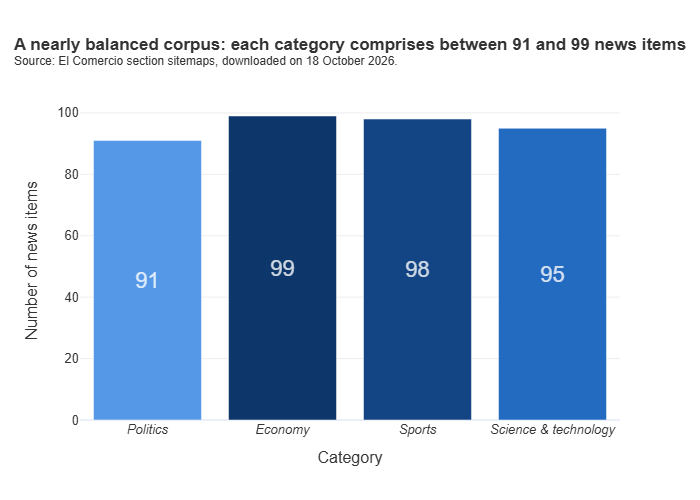

In [71]:
conteo_categorias = noticias["categoria"].value_counts().reset_index()
conteo_categorias.columns = ["categoria", "noticias"]

fig = px.bar(
    conteo_categorias, x="categoria", y="noticias", color="noticias", text="noticias",
    color_continuous_scale=escala_azules,
    category_orders={"categoria": orden_categorias},
    labels={"categoria": "Category", "noticias": "Number of news items"},
    title="<b>A nearly balanced corpus: each category comprises between 91 and 99 news items</b><br>" + fuente_grafico,
)
# Values centered inside the bars, in semi-transparent white.
fig.update_traces(
    textposition="inside", insidetextanchor="middle",
    textfont=dict(size=22, color="rgba(255, 255, 255, 0.8)"),
)
aplicar_estilo(fig).show()

The four categories exhibit a nearly balanced distribution, with a maximum difference of only eight items between Economy (99) and Politics (91); the color gradient reinforces this reading, insofar as darker shades denote larger categories. This balance is methodologically relevant: since no category clearly dominates the dataset, the classifier trained in Part 2 is less likely to favor a majority class, and macro-averaged metrics will therefore provide a fair assessment of its performance across all categories.

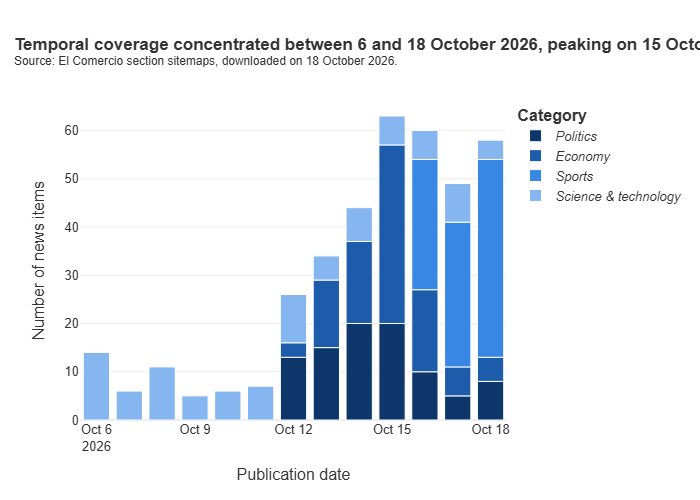

In [72]:
noticias_por_fecha = noticias.groupby(["fecha", "categoria"]).size().reset_index(name="noticias")

fig = px.bar(
    noticias_por_fecha, x="fecha", y="noticias", color="categoria",
    color_discrete_map=colores_categorias,
    category_orders={"categoria": orden_categorias},
    labels={"fecha": "Publication date", "noticias": "Number of news items", "categoria": "Category"},
    title="<b>Temporal coverage concentrated between 6 and 18 October 2026, peaking on 15 October</b><br>" + fuente_grafico,
)
# A thin white line separates the stacked segments.
fig.update_traces(marker_line_color="white", marker_line_width=1)
aplicar_estilo(fig).show()

The collected news span from 6 to 18 October 2026, with a noticeable peak on 15 October. This temporal concentration stems from the very nature of the sitemaps, which only list the most recent articles of each section. Consequently, the dataset reflects the news agenda of a specific two-week period, which constitutes a limitation: the vocabulary associated with each category may be shaped by the particular events of those days, thereby reducing the temporal generalizability of the classifier.

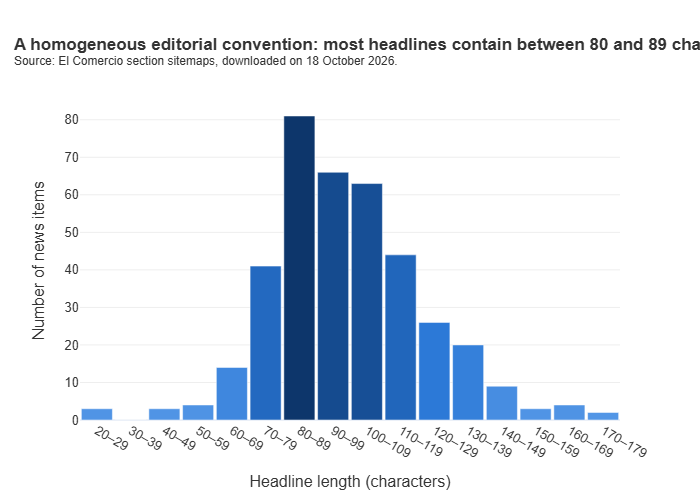

In [73]:
# Headline length in characters, used only for exploration.
noticias["longitud_titular"] = noticias["titular"].str.len()

# 10-character intervals (e.g. "80–89") make the distribution easier to read.
inicio = noticias["longitud_titular"].min() // 10 * 10
fin = noticias["longitud_titular"].max() // 10 * 10 + 10
cortes = list(range(inicio, fin + 1, 10))
etiquetas = [f"{corte}–{corte + 9}" for corte in cortes[:-1]]

noticias["rango_longitud"] = pd.cut(noticias["longitud_titular"], bins=cortes, labels=etiquetas, right=False)
histograma = noticias["rango_longitud"].value_counts(sort=False).reset_index()
histograma.columns = ["rango_longitud", "noticias"]

fig = px.bar(
    histograma, x="rango_longitud", y="noticias", color="noticias",
    color_continuous_scale=escala_azules,
    labels={"rango_longitud": "Headline length (characters)", "noticias": "Number of news items"},
    title="<b>A homogeneous editorial convention: most headlines contain between 80 and 89 characters</b><br>" + fuente_grafico,
)
fig.update_layout(bargap=0.08)
aplicar_estilo(fig).show()

Headline lengths are grouped into ten-character intervals, and the darkest bar reveals that most headlines contain between 80 and 89 characters. This concentration suggests that El Comercio adheres to a relatively homogeneous editorial convention. From a modelling perspective, it also implies that each headline offers a limited amount of textual information; accordingly, the `bajada` may serve as a valuable complementary input in subsequent stages.

## 6. Validation of headline lengths

In order to verify the coherence of the histogram, the five longest and the five shortest headlines are inspected directly.

In [75]:
# Show the complete text of each headline instead of truncating it.
pd.set_option("display.max_colwidth", None)

noticias.sort_values("longitud_titular", ascending=False)[["titular", "longitud_titular", "etiqueta"]].head(5)

,titular,longitud_titular,etiqueta
199,"“El jugador peruano tiene un déficit grande en nutrición y táctica que resuelve a los 20 años, eso en Argentina es a los 12″: Urciuoli, el técnico revelación con Alianza Atlético",178,deportes
200,El furioso “Que se dedique a administrar” de Guede a Franco Velazco y un Quevedo que reconquistó a Comando Sur: Lo que no se vio del 3-1 que mantiene a Alianza en la pelea,171,deportes
261,“Creo que puedo llegar a un top 3 sin que nadie se quede botado”: Raúl ‘Mono’ Orlandini le responde a El Comercio sobre las dos últimas etapas de Caminos del Inca 2026,167,deportes
57,"Keiko Fujimori sobre Álvaro Vargas Llosa: “Confío en que su trayectoria, experiencia y compromiso contribuirán a fortalecer relaciones bilaterales y lazos de amistad”",166,politica
268,"“El día de mañana me encantaría ver a tantas niñas entrando al automovilismo”: Annia Cillóniz, líder en la categoría S1600, sobre sus sueños en Caminos del Inca",160,deportes


The five longest headlines are displayed first, in descending order of length, so that the upper tail of the histogram can be inspected directly.

In [76]:
noticias.sort_values("longitud_titular")[["titular", "longitud_titular", "etiqueta"]].head(5)

,titular,longitud_titular,etiqueta
155,Invocación por el Perú,22,economia
99,AlaCena no tiene precio,23,economia
117,IA y Sandbox regulatorio,24,economia
169,La evolución de la confianza en los pagos,41,economia
100,Premio Nobel de Economía: la macro es micro,43,economia


The extreme cases are consistent with the tails of the histogram. On the one hand, the longest headlines (160–180 characters) are predominantly interview-based items that open with a verbatim quotation followed by the speaker's identification; notably, four of the five belong to the sports category. On the other hand, the shortest headlines (22–43 characters) all belong to the economy category and appear to be titles of opinion columns, such as *"AlaCena no tiene precio"* or *"IA y Sandbox regulatorio"*. Since none of these cases reflects an extraction error, all of them are retained in the dataset. Nevertheless, the short economy headlines deserve particular attention in Part 2: given their creative wording and the absence of explicit economic vocabulary, they are likely to be among the most difficult items to classify.

## 7. Export

Finally, the clean dataset is exported with the seven mandatory columns, thereby excluding the auxiliary columns created exclusively for the exploratory analysis.

In [77]:
noticias_final = noticias[columnas_finales]
noticias_final.to_csv("datos/noticias.csv", index=False)

print(noticias_final.shape)
noticias_final.head()

(383, 7)


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,Jorge Nieto dice que se reunió con el Ejecutivo: “Aprobemos los 20 puntos y hágannos llegar como proyecto de ley los otros 7”,"Jorge Nieto, líder del Partido del Buen Gobierno, reveló que sostuvo una reunión con “altos niveles del Ejecutivo”, para presentar una propuesta que permita destrabar las discrepancias en torno a la aprobación de las facultades legislativas. Según indicó, el encuentro tuvo una respuesta favorable y permitió alcanzar un “preacuerdo”.",El Comercio,politica-gobierno,https://elcomercio.pe/politica/gobierno/jorge-nieto-dice-que-se-reunio-con-el-ejecutivo-aprobemos-los-20-puntos-y-hagannos-llegar-como-proyecto-de-ley-los-otros-7-puntos-que-consideran-imprescindibles-ultimas-apuesplan-noticia/,2026-10-18,politica
1,Álvaro Vargas Llosa: “EE.UU. nos está ayudando a recuperar la soberanía que las mafias ponen en peligro”,"Álvaro Vargas Llosa Asumirá el cargo el 16 de noviembre, pero en esta conversación adelanta lo que serán varias claves de su gestión. También hace una lectura sobre la manera que tiene la administración Trump de aproximarse al Perú, la relación comercial y el factor geopolítico.",El Comercio,politica,https://elcomercio.pe/politica/alvaro-vargas-llosa-eeuu-embajador-del-peru-en-estados-unidos-entrevista-noticia/,2026-10-18,politica
2,"El Senado también se la juega, una crónica de Fernando Vivas sobre la pugna por las facultades legislativas","Tras la agónica aprobación de facultades acotadas en Diputados, con Fuerza Popular apostando al todo o nada; en el senado también se la siguen jugando por reponer algo de lo acotado.",El Comercio,politica,https://elcomercio.pe/politica/el-senado-tambien-se-la-juega-una-cronica-de-fernando-vivas-congreso-facultades-legislativas-keiko-fujimori-gobierno-apuesplan-noticia/,2026-10-18,politica
3,El voto 31: Este es el escenario que muestra el peso de Obras para el fujimorismo en la delegación de facultades,Los cinco senadores del partido de Ricardo Belmont serán piezas clave si es que se insiste con la modificación del texto de delegación de facultades recibido desde la Cámara de Diputados.,El Comercio,politica,https://elcomercio.pe/politica/el-voto-31-este-es-el-escenario-que-muestra-el-peso-de-obras-para-el-fujimorismo-en-la-delegacion-de-facultades-congreso-keiko-fujimori-senado-apuesplan-noticia/,2026-10-18,politica
4,Comisión de Constitución del Senado reanuda este lunes debate sobre el pedido de facultades legislativas,La Comisión de Constitución del Senado continuará este lunes con la sesión extraordinaria en la que se debatía la delegación de facultades legislativas al Ejecutivo en las materias de fenómeno El Niño y Seguridad Ciudadana.,El Comercio,politica,https://elcomercio.pe/politica/comision-de-constitucion-del-senado-reanuda-este-lunes-debate-sobre-facultades-al-ejecutivo-en-seguridad-y-fen-apuesplan-noticia/,2026-10-18,politica


The final file `datos/noticias.csv` contains 383 news items and the seven columns required by the assignment, arranged in the specified order. This dataset constitutes the input for the classification stage developed in `02_clasificacion.ipynb`.

## Summary

| Step | What was done | Key output |
|---|---|---|
| Preliminary assessment | La República's RSS was tested and found insufficient (around 21 items per feed) | Change to El Comercio (Option B) |
| URL collection | Four section sitemaps were downloaded, with raw XML backups | 400 article URLs |
| Field extraction | Each article was visited to extract its Open Graph metadata, with one retry at most | `datos/raw/noticias_crudas.csv` |
| Cleaning | Failed requests, duplicates and empty headlines were removed; sections were mapped onto four categories | 17 items discarded |
| Exploratory analysis | Three interactive Plotly charts with analytical titles | Balanced categories (91–99 items) |
| Validation | The longest and shortest headlines were inspected | No extraction errors detected |
| Export | Dataset with the seven mandatory columns | `datos/noticias.csv` (383 × 7) |

## AI use statement

In accordance with the course guidelines, which explicitly permit the use of AI assistants, Claude (Anthropic) was used as a tutoring and coding support tool during the development of this notebook. Specifically, it assisted in structuring the scraping and cleaning code, troubleshooting environment errors, and refining the academic wording of the explanatory cells. Nevertheless, all methodological decisions were made and verified by the author: the assessment of La República's feeds and the subsequent change of outlet, the definition of the section-to-category mapping, the manual inspection of discarded and extreme headlines, and the interpretation of every chart. Furthermore, all code was executed, reviewed and validated against its outputs by the author.

## References

El Comercio. (2026). *robots.txt*. Retrieved October 18, 2026, from https://elcomercio.pe/robots.txt

La República. (2026). *robots.txt*. Retrieved October 18, 2026, from https://larepublica.pe/robots.txt

McKinney, W. (2010). Data structures for statistical computing in Python. In S. van der Walt & J. Millman (Eds.), *Proceedings of the 9th Python in Science Conference* (pp. 56–61). https://doi.org/10.25080/Majora-92bf1922-00a

Mitchell, R. (2018). *Web scraping with Python: Collecting more data from the modern web* (2nd ed.). O'Reilly Media.

Open Graph Protocol. (n.d.). *The Open Graph protocol*. Retrieved October 18, 2026, from https://ogp.me/

Plotly Technologies Inc. (2015). *Collaborative data science*. Plotly Technologies Inc. https://plot.ly

Quispe, A. (2026). *Fundamentos de Python para Ciencias Sociales y Gestión Pública* [Course repository]. GitHub. https://github.com/alexanderquispe/Diplomado_PUCP

Reitz, K. (n.d.). *Requests: HTTP for humans* [Software documentation]. Retrieved October 18, 2026, from https://requests.readthedocs.io/

Richardson, L. (n.d.). *Beautiful Soup documentation*. Retrieved October 18, 2026, from https://www.crummy.com/software/BeautifulSoup/bs4/doc/

Sitemaps.org. (n.d.). *Sitemaps XML format*. Retrieved October 18, 2026, from https://www.sitemaps.org/protocol.html